# 05 · Today's plan

The final book (04, step 4, the defaults in `config/strategy.yaml`) at the latest close in the
data. The current book and stop state come from `state/book.json` if present.
Research output - nothing is traded.

In [1]:
# run from the project root (works from research/ or any subfolder); the strategy package is
# in src/, the data download and plot style in research/lib
import os, sys
while not os.path.isdir("config") and os.path.dirname(os.getcwd()) != os.getcwd():
    os.chdir("..")
sys.path[:0] = [os.path.abspath("src"), os.path.abspath("research/lib")]

In [2]:
import pandas as pd, matplotlib.pyplot as plt
from betafunding import load_config, load_panel, build_signals, plan, to_markdown, load_book, roll_forward
from plotstyle import *
from IPython.display import Markdown, display
apply()
cfg = load_config()
panel = load_panel(**cfg["data"])
sig = build_signals(panel, cfg)
as_of, equity, w_old, stops = load_book("state/book.json", cfg["equity_usd"])
w_old = roll_forward(panel, cfg, as_of, w_old, stops)
summary, tbl = plan(panel, sig, cfg, w_old, stops, equity)
display(Markdown(to_markdown(summary, tbl)))

### Daily rebalance (2026-09-30)
- Equity: $10,000
- Net beta: BTC +0.020, ETH +0.020 (target 0)
- Expected funding: 89.8% APY
- Gross: 0.19x · turnover 19.5% (fee 0.010%) · solver no_trade_band
- Stopped out (cooling down): none

| Coin | Side | Current | Target | Trade | BTC beta | ETH beta | Funding fcst APY |
| --- | --- | --- | --- | --- | --- | --- | --- |
| ETH | SHORT | 0.0% | -5.9% | sell $591 | 0.00 | 1.00 | 5% |
| BTC | SHORT | 0.0% | -1.4% | sell $139 | 1.00 | -0.00 | 5% |
| ARK | LONG | 0.0% | 12.2% | buy $1,218 | 0.28 | 0.65 | -734% |

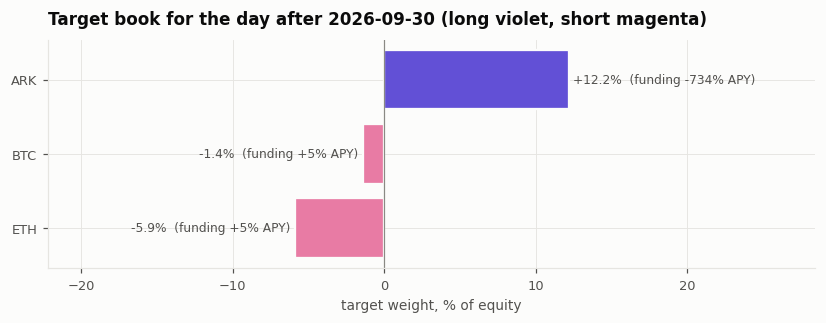

In [3]:
t = tbl.sort_values("target_%")
fig, ax = plt.subplots(figsize=(9, 0.5 * len(t) + 1.2))
cols = [LEG["long"] if v > 0 else LEG["short"] for v in t["target_%"]]
r = ax.barh(t.index, t["target_%"], color=cols, edgecolor=SURFACE, lw=1.5)
ax.bar_label(r, labels=[f"{v:+.1f}%  (funding {f:+.0f}% APY)" for v, f in zip(t["target_%"], t["funding_fcst_apy_%"])],
             fontsize=8, color=INK2, padding=3)
ax.axvline(0, color=MUTED, lw=0.8); ax.set_xlabel("target weight, % of equity")
lo, hi = min(t["target_%"].min(), 0), max(t["target_%"].max(), 0)
ax.set_xlim(lo - 0.9 * (hi - lo) * (lo < 0), hi + 0.9 * (hi - lo))   # room for the labels on both sides
ax.set_title(f"Target book for the day after {summary['day']} (long violet, short magenta)")
save(fig, "today_book"); plt.show()